In [20]:
import numpy as np
import rasterio
from rasterio import Affine

location = 'Thames1'
region = 'Region1'
# 定义年份列表
year_list = [2019, 2020, 2021, 2022, 2023]
year = 2019
year_after = 2024


# paths
dem1_path = f'G:/ICESat-2/{region}_map/{location}_map/A{year}/{location}_{year}_4_RF_FB6_new9_bys.tif'
dem2_path = f'G:/ICESat-2/{region}_map/{location}_map/A{year_after}/{location}_{year_after}_4_RF_FB6_new9_bys.tif'

# user-provided single-file RMSE (or arrays)
rmse1 = 0.34 # m, or load raster of sigma per pixel
rmse2 = 0.35

A_pix = 30.0 * 30.0  # pixel area in m^2 (example: 10m resolution)

# read
with rasterio.open(dem1_path) as src:
    dem1 = src.read(1)
    profile = src.profile
with rasterio.open(dem2_path) as src:
    dem2 = src.read(1)

# mask nodata
mask = (dem1 != profile['nodata']) & (dem2 != profile['nodata'])

dh = np.full_like(dem1, np.nan, dtype=float)
dh[mask] = dem2[mask] - dem1[mask]

# sigma_delta per pixel (here single value; replace with raster if available)
sigma_delta = np.sqrt(rmse1**2 + rmse2**2)
LoD = sigma_delta  # 95% CI

# significant masks
acc_mask = (dh > LoD)
ero_mask = (dh < -LoD)

# volume change
deltaV = (np.nansum(dh[acc_mask] * A_pix) + np.nansum(dh[ero_mask] * A_pix))/1e6  # signed
# or sum all dh*area if you want net (including small non-significant)
netV = np.nansum(dh[mask] * A_pix)/1e6

acc_mask_netV = np.nansum(dh[acc_mask] * A_pix)/1e6
ero_mask_netV = np.nansum(dh[ero_mask] * A_pix)/1e6
# uncertainty on volume (assuming pixel errors independent)
N = np.sum(mask)
sigma_V = A_pix * np.sqrt(N) * sigma_delta  # if same sigma per pixel

print("LoD (m):", LoD)
print("Net volume change (m3):", netV)
print('ero_mask_netV', ero_mask_netV)
print('acc_mask_netV',acc_mask_netV)

print("Signed significant volume (m3):", deltaV)
print("Estimated sigma_V (m3):", sigma_V)


LoD (m): 0.4879549159502341
Net volume change (m3): -5.005221734720824
ero_mask_netV -17.445402241533994
acc_mask_netV 26.769293125355244
Signed significant volume (m3): 9.32389088382125
Estimated sigma_V (m3): 724493.269533955


In [13]:
import numpy as np
import rasterio
from rasterio import Affine

location = 'Solway'
region = 'Region4'
# 定义年份列表
year_list = [2019, 2020, 2021, 2022, 2023]
# year = 2019
# year_after = 2024

for year in year_list:
    dem1_path = f'G:/ICESat-2/{region}_map/{location}_map/A{year}/{location}_{year}_4_RF_FB6_new9_bys.tif'
    with rasterio.open(dem1_path) as src:
        dem1 = src.read(1)
        profile = src.profile

    A_pix = 30.0 * 30.0
    
    Sum_area = np.nansum(dem1 * A_pix)/1e6
    print(Sum_area)

348.141824
221.232592
198.758784
185.097568
181.84528



Common valid region area: 297.76 km²

Processing 2019 → 2020 ...
  LoD = 1.114 m
  Erosion volume:  -38.65 ×10⁶ m³
  Accretion volume:6.04 ×10⁶ m³

Processing 2020 → 2021 ...
  LoD = 1.256 m
  Erosion volume:  -10.82 ×10⁶ m³
  Accretion volume:27.34 ×10⁶ m³

Processing 2021 → 2022 ...
  LoD = 1.020 m
  Erosion volume:  -80.58 ×10⁶ m³
  Accretion volume:2.72 ×10⁶ m³

Processing 2022 → 2023 ...
  LoD = 1.005 m
  Erosion volume:  -9.37 ×10⁶ m³
  Accretion volume:31.31 ×10⁶ m³

Processing 2023 → 2024 ...
  LoD = 0.998 m
  Erosion volume:  -14.39 ×10⁶ m³
  Accretion volume:56.08 ×10⁶ m³


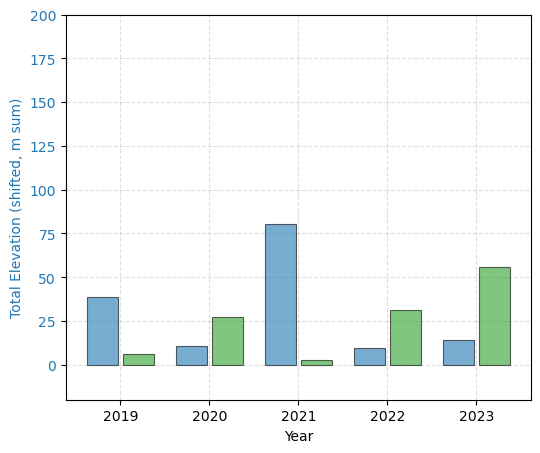

In [58]:
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt
import os

# ---------- 参数 ----------
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
RMSEs = [0.49, 1.00, 0.76, 0.68, 0.74, 0.67]
# RMSEs = [0.67, 0.67, 0.67, 0.67, 0.67, 0.67]
dems = []
for year in year_list:
    path = f'G:/ICESat-2/Region4_map/Morecambe_map/A{year}/Morecambe_{year}_4_RF_FB6_new9_bys.tif'
    dem = rxr.open_rasterio(path, masked=True).squeeze()
    dem = dem.astype(float)
    dems.append(dem)

# ---------- 获取像元面积 ----------
xres, yres = dems[0].rio.resolution()
pixel_area_m2 = abs(xres * yres)

# ---------- 计算所有年份的有效区交集 ----------
valid_mask = np.ones_like(dems[0].values, dtype=bool)
for dem in dems:
    valid_mask &= np.isfinite(dem.values) & (dem.values != 0)

intersect_area = (np.count_nonzero(valid_mask)) * pixel_area_m2 / 1e6
print(f"\nCommon valid region area: {intersect_area:.2f} km²")

# ---------- 年际差分 ----------
ero_list, acc_list = [], []
for (year1, dem1, RMSE1), (year2, dem2, RMSE2) in zip(
        zip(year_list[:-1], dems[:-1], RMSEs[:-1]),
        zip(year_list[1:],  dems[1:],  RMSEs[1:])):

    print(f"\nProcessing {year1} → {year2} ...")

    # DEM差异（正值=淤积，负值=侵蚀）
    diff = np.full_like(dem1, np.nan, dtype=float)
    diff[valid_mask] = dem2.values[valid_mask] - dem1.values[valid_mask]

    # 计算检测限 (LoD)
    LoD = np.sqrt(RMSE1**2 + RMSE2**2)  # 95%置信水平

    # 显著变化 Mask
    acc_mask = (diff > LoD)
    ero_mask = (diff < -LoD)

    # 统计区域变化
    erosion_volume = np.nansum(diff[ero_mask] * pixel_area_m2) / 1e6
    accretion_volume = np.nansum(diff[acc_mask] * pixel_area_m2)/ 1e6
    ero_list.append(erosion_volume)
    acc_list.append(accretion_volume)

    print(f"  LoD = {LoD:.3f} m")
    print(f"  Erosion volume:  {erosion_volume:.2f} ×10⁶ m³")
    print(f"  Accretion volume:{accretion_volume :.2f} ×10⁶ m³")

    # 可视化
    # plt.figure(figsize=(8, 5))
    # plt.imshow(diff, cmap='RdBu', vmin=-4, vmax=4)
    # plt.colorbar(label='Elevation Change (m)')
    # plt.title(f"Elevation Change {year1}-{year2}")
    # plt.tight_layout()
    # plt.show()



year_list = [2019, 2020, 2021, 2022, 2023]
x = np.array(year_list)
fig, ax1 = plt.subplots(figsize=(6, 5))
ax1.set_ylim(-20, 200)


bar_width = 0.35
gap = 0.05           # 两组柱子之间的间隔

# 计算偏移（确保中间留出空隙）
x1 = [y - (bar_width/2 + gap/2) for y in year_list]
x2 = [y + (bar_width/2 + gap/2) for y in year_list]

# 绘制第一组柱子（蓝色）
ax1.bar(x1, np.array(np.abs(ero_list)), 
        width=bar_width, color='tab:blue', alpha=0.6, 
        edgecolor='black', linewidth=0.8, label='Total Tidal-flat Area (km²)', zorder=2)

# 绘制第二组柱子（绿色）
ax1.bar(x2, np.array(acc_list), 
        width=bar_width, color='tab:green', alpha=0.6, 
        edgecolor='black', linewidth=0.8, label='Tidal-flat Area (km²)', zorder=2)

ax1.set_xticks(year_list)
ax1.set_xticklabels(year_list)
# ax1.scatter(x ,np.array(np.abs(ero_list)), color='tab:blue', label='Total Elevation (shifted sum)',zorder=2)
# ax1.scatter(x ,np.array(acc_list), color='tab:green', label='Total Elevation (shifted sum)',zorder=2)
# ax1.plot(x_smooth, y_smooth, color='tab:red', linestyle='--', label='Poly fit (2nd order)',zorder=1)
ax1.set_xlabel('Year')
ax1.set_ylabel('Total Elevation (shifted, m sum)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, linestyle='--', alpha=0.4)


In [75]:
RMSE1 = 0.05
LoD = 1.96*np.sqrt(RMSE1**2 + RMSE1**2)
LoD

0.13859292911256335

In [ ]:
['#0000ff', '#00ffff', '#ffff00', '#ff0000', '#ffffff']
['#4A76A8', '#9BAFB7', '#FFF9B0', '#F29060', '#D63E31']

In [12]:
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt
import os

year_list = [2019, 2020, 2021, 2022, 2023]
year_list = [2019]
location = 'Morecambe'
region = 'Region4'
RMSEs = [0.49, 1.00, 0.76, 0.68, 0.74, 0.67]
# RMSEs = [0.67, 0.67, 0.67, 0.67, 0.67, 0.67]
dems = []
for year in year_list:
    year_before = year
    year_after = year + 5
    path1 = f'G:/ICESat-2/{region}_map/{location}_map/A{year_before}/{location}_{year_before}_4_RF_FB6_new9_bys_C.tif'
    path2 = f'G:/ICESat-2/{region}_map/{location}_map/A{year_after}/{location}_{year_after}_4_RF_FB6_new9_bys_C.tif'
    output =  f'G:/ICESat-2/{region}_map/{location}_map/DOD/{location}_{year_after}_{year_before}_4_RF_FB6_new9_bys.tif'
    
    
    
    DEM_before = rxr.open_rasterio(path1, masked=True).squeeze()
    DEM_after = rxr.open_rasterio(path2, masked=True).squeeze()
    
    DIFF = DEM_after - DEM_before
    DIFF = DIFF.where((~np.isnan(DEM_before)) & (~np.isnan(DEM_after)) & (DEM_after!=0) & (DEM_before!=0))

    output_dir = os.path.dirname(output)
    os.makedirs(output_dir, exist_ok=True)
    

    DIFF.rio.to_raster(output)
    print(f"saving DOD as :", {output})
        

    # plt.figure(figsize=(8, 4))
    # DIFF.plot(cmap='RdBu', vmin=-4, vmax=4)
    # plt.title(f'Tidal-flat elevation change ({year}–{year_after})')
    # plt.xlabel('Longitude')
    # plt.ylabel('Latitude')
    # plt.show()

saving DOD as : {'G:/ICESat-2/Region4_map/Morecambe_map/DOD/Morecambe_2024_2019_4_RF_FB6_new9_bys.tif'}


In [6]:
import rioxarray
import geopandas as gpd

# 读取栅格和矢量
year_list = [2019, 2020, 2021, 2022, 2023, 2024]

location = 'Solway'
region = 'Region4'
gdf = gpd.read_file("G:\ICESat-2\Region4_map\Solway_map\Solway_range.shp")
for year in year_list: 
    
    path = f'G:/ICESat-2/{region}_map/{location}_map/A{year}/{location}_{year}_4_RF_FB6_new9_bys.tif'
    output = f'G:/ICESat-2/{region}_map/{location}_map/A{year}/{location}_{year}_4_RF_FB6_new9_bys_C.tif'
    rds = rioxarray.open_rasterio(path)
    # 矢量投影与栅格一致（如需）
    gdf = gdf.to_crs(rds.rio.crs)

    # 一行裁剪
    clipped = rds.rio.clip(gdf.geometry, gdf.crs)

    # 保存结果
    clipped.rio.to_raster(output)

    print("✅ 裁剪完成！",f'{output}')


✅ 裁剪完成！ G:/ICESat-2/Region4_map/Solway_map/A2019/Solway_2019_4_RF_FB6_new9_bys_C.tif
✅ 裁剪完成！ G:/ICESat-2/Region4_map/Solway_map/A2020/Solway_2020_4_RF_FB6_new9_bys_C.tif
✅ 裁剪完成！ G:/ICESat-2/Region4_map/Solway_map/A2021/Solway_2021_4_RF_FB6_new9_bys_C.tif
✅ 裁剪完成！ G:/ICESat-2/Region4_map/Solway_map/A2022/Solway_2022_4_RF_FB6_new9_bys_C.tif
✅ 裁剪完成！ G:/ICESat-2/Region4_map/Solway_map/A2023/Solway_2023_4_RF_FB6_new9_bys_C.tif
✅ 裁剪完成！ G:/ICESat-2/Region4_map/Solway_map/A2024/Solway_2024_4_RF_FB6_new9_bys_C.tif


In [1]:

import numpy as np
import pandas as pd
import os
import rioxarray as rxr
from osgeo import gdal
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline, make_pipeline
import geopandas as gpd
import rasterio
from shapely.geometry import box
from shapely.geometry import Point
from rasterio.sample import sample_gen
import xgboost as xgb

from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from skopt import BayesSearchCV
from skopt.space import Integer, Real

c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [6]:
def save_img(output_filename, reference_filename, array):
    
    reference = gdal.Open(reference_filename)
    
    # 获取地理变换参数和坐标系
    geo_transform = reference.GetGeoTransform()
    projection = reference.GetProjection()

    # 获取矩阵尺寸
    rows, cols = array.shape

    # 创建新的 TIFF 数据集
    driver = gdal.GetDriverByName('GTiff')
    out_data = driver.Create(output_filename, cols, rows, 1, gdal.GDT_Float32)

    # 设置地理变换和坐标系
    out_data.SetGeoTransform(geo_transform)
    out_data.SetProjection(projection)
    

    # 写入数据
    out_data.GetRasterBand(1).WriteArray(array)

    # 保存并关闭文件
    out_data.FlushCache()
    out_data = None
    
def load_refer_icesat_point(FB_raster, icesat_csv_path, output_point, output_raw_point):
    
    df = pd.read_csv(icesat_csv_path)
    lon, lat = 'mean_lon', 'mean_lat'
    LULC_path = "E:/Downloads/tes/UK_LULC.tif"
    geometry = [Point(xy) for xy in zip(df[lon], df[lat])]
    gdf = gpd.GeoDataFrame(df, geometry=geometry)
    gdf.set_crs(epsg=4326, inplace=True)
    points = gdf
    
    with rasterio.open(FB_raster) as src:
        
        if points.crs != src.crs:
            points = points.to_crs(src.crs)
        coords = [(point.x, point.y) for point in points.geometry]
        values = list(src.sample(coords))
        
        band_count = src.count
        for band in range(band_count):
            points[f"b{band+1}_FB6"] = [v[band] for v in values]
            
    # with rasterio.open(LULC_path) as src:

    #     if points.crs != src.crs:
    #         points = points.to_crs(src.crs)
    #     coords = [(point.x, point.y) for point in points.geometry]
    #     values = list(src.sample(coords))

    #     band_count = src.count
    #     points['LULC'] = [v[0] for v in values] 
     
    icesat_mask = (points['OH'] < 5) & (points['b7_FB6'] > 0) #& ((points['LULC'] == 200) | (points['LULC'] == 80))
    data = points[icesat_mask]
    
    points.to_file(output_raw_point)
    data.to_file(output_point)
    
    return data

def optimize_random_forest(x_train, y_train,  n_iter=30, cv=3):

    # if feature_columns is None:
    #     raise ValueError("feature_columns must be provided.")

    classifier = RandomForestRegressor(random_state=42)

    search_space = {
        'n_estimators': Integer(50, 500),
        'max_depth': Integer(3, 20),
        'min_samples_split': Integer(2, 20),
        'min_samples_leaf': Integer(1, 20),
        'max_features': Real(0.1, 1.0)
    }

    opt = BayesSearchCV(
        estimator=classifier,
        search_spaces=search_space,
        n_iter=n_iter,
        cv=cv,
        scoring='neg_mean_squared_error',
        random_state=42,
        n_jobs=-1
    )

    opt.fit(x_train, y_train)

    best_params = opt.best_params_
    print('Best hyperparameters:', best_params)
    print('Best score (negative MSE):', opt.best_score_)

    # 使用最优参数重新训练模型
    final_model = RandomForestRegressor(**best_params, random_state=42)
    # final_model.fit(x_train, y_train)

    return best_params, final_model

In [7]:
year = 2019
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
join_info = ['Region3', 'Region3b1']
join_info2 = ['Region2', 'wash_bay']
ICESat_points_list = []
for year in year_list:
    ICESat_path = f'G:\ICESat-2\{join_info[0]}_map\{join_info[1]}_map\A{year}\A_{join_info[1]}_30m_{year}_new10.shp' 
    ICESat_path_ = f'G:\ICESat-2\{join_info2[0]}_map\{join_info2[1]}_map\A{year}\A_{join_info2[1]}_30m_{year}_new10.shp'
    k = gpd.read_file(ICESat_path)
    k2 = gpd.read_file(ICESat_path_)
    ICESat_points_list.append(k.to_crs(epsg=4326))
    ICESat_points_list.append(k2.to_crs(epsg=4326))
data = pd.concat(ICESat_points_list)
len(data)

21901

In [ ]:
#----------------------------all ICESat-2 used to train RF modal -----------------------------------------
# Base info

region = 'Region6'
location_list = ['Region6d']
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
method = 'RF'
band = 4

join_info = ['Region5', 'Region5e']
join_info2 = ['Region5', 'Region5g']

for i in range(len(location_list)):
    
    location = location_list[i]
    
    LULC_path = "E:/Downloads/tes/UK_LULC.tif"
    LULC = rxr.open_rasterio(LULC_path, masked=True).squeeze()
    target_band, target_id = ['b1_FB6','b2_FB6','b3_FB6','b4_FB6'], [0, 1, 2, 3]
    #target_band, target_id = ['b1_FB6'], [0]
    
    # load classifer  
    #---------------------------------------------------------
    # ICESat_points_list = []
    # for k in range(len(year_list)):
        
    #     FB_raster_path_ = f"G:\ICESat-2\{region}_map\{location}_map\A{year_list[k]}/{location}_{year_list[k]}_FB6_new9.tif"
        
    #     ICESAT_csv_path_ = f'G:\ICESat-2\{region}\{region}_{location}\A_{location}_30m_{year_list[k]}_new10.csv'
    #     output_raw_point = f'G:\ICESat-2\{region}_map\{location}_map\A{year_list[k]}\A_{location}_30m_{year_list[k]}_raw_new10.shp'
    #     output_point = f'G:\ICESat-2\{region}_map\{location}_map\A{year_list[k]}\A_{location}_30m_{year_list[k]}_new10.shp'
    #     data = load_refer_icesat_point(FB_raster_path_, ICESAT_csv_path_, output_point, output_raw_point)
            
    #     ICESat_points_list.append(data.to_crs(epsg=4326))
    
    year_list = [2019, 2020, 2021, 2022, 2023, 2024]
    ICESat_points_list = []
    for year in year_list:
        ICESat_path__ = f'G:\ICESat-2\{join_info2[0]}_map\{join_info2[1]}_map\A{year}\A_{join_info2[1]}_30m_{year}_new10.shp' 
        ICESat_path_ = f'G:\ICESat-2\{join_info[0]}_map\{join_info[1]}_map\A{year}\A_{join_info[1]}_30m_{year}_new10.shp' 
        ICESat_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.shp'
        k = gpd.read_file(ICESat_path)
        k2 = gpd.read_file(ICESat_path_)
        k3 = gpd.read_file(ICESat_path__)
        ICESat_points_list.append(k.to_crs(epsg=4326))
        ICESat_points_list.append(k2.to_crs(epsg=4326))
        ICESat_points_list.append(k3.to_crs(epsg=4326))
    #---------------------------------------------------------
    
    data = pd.concat(ICESat_points_list)
    y_train = data['OH'].values
    x_train = data[target_band].values
    
    if method == 'RF':
        best_params, classifier = optimize_random_forest(x_train, y_train)
        classifier.fit(x_train, y_train)
    elif method == 'Linear':
        classifier = np.polyfit(x_train[:, 0], y_train, deg=1)
    else:
        classifier = np.polyfit(x_train[:, 0], y_train, deg=2)
    
    for j in range(len(year_list)):
      
        # Input info 
        FB_raster_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year_list[j]}/{location}_{year_list[j]}_FB6_new9.tif"
    
        # Output Info
        output_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year_list[j]}\{location}_{year_list[j]}_{band}_{method}_FB6_new9_bys_join.tif'


        if not os.path.exists(FB_raster_path):
            print(FB_raster_path, ' is not exist!')
            break
       

        # Elevation mapping
        raster = rxr.open_rasterio(FB_raster_path).values
        raster = np.nan_to_num(raster, nan = 0)
        selected_raster = raster[target_id, :, :]

        if len(selected_raster.shape) != 3:
            row, col = selected_raster.shape
            selected_raster = selected_raster.reshape(1, row, col)
        else: 
            bands, row, col = selected_raster.shape

        print('selected_raster.shape', selected_raster.shape)

        k = 0
        result = np.array([[]])
        for i in range(row):
            
            x_train = np.transpose(selected_raster[:, i, :])
            if method == 'RF':
                y_pred = classifier.predict(x_train)
            elif method == 'Linear':
                y_pred = np.polyval(classifier, x_train)
            else:
                y_pred = np.polyval(classifier, x_train)
            
            result = np.append(result, y_pred)
            
            if i%(int(row/5)) == 0:
                
                print(k*20 , '%_ is done')
                k = k+1
        
        result = result.reshape(row, col)
        print(result.shape, type(result))
        # tf_mask = raster[6,:,:].flatten()
        # result[tf_mask == 0] = 0
        # result_ = result.reshape(row, col)
        tf_mask = raster[6,:,:]#.flatten()
        # Freq_s2 = raster[5,:,:]#.flatten()
        
        z = rxr.open_rasterio(FB_raster_path, masked=True).squeeze() 
        LULC_aligned = LULC.rio.reproject_match(z)
        
        #result[(tf_mask == 0) | ((LULC_aligned != 200) & (LULC_aligned != 80))] = 0
        result[(tf_mask == 0)] = 0       

        save_img(output_path, FB_raster_path, result)
        print(f'{location}_{year_list[j]} is output to {output_path}')